In [1]:
import numpy as np
import polars as pl
import scipy as sp
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
files = [file for file in Path("data").iterdir() if file.is_file()]
files

[PosixPath('data/fr_prop_pid.csv'),
 PosixPath('data/fr_turn_pid.csv'),
 PosixPath('data/fr_turn_pid_ground.csv')]

In [3]:
data = {file.stem: pl.read_csv(file) for file in files}

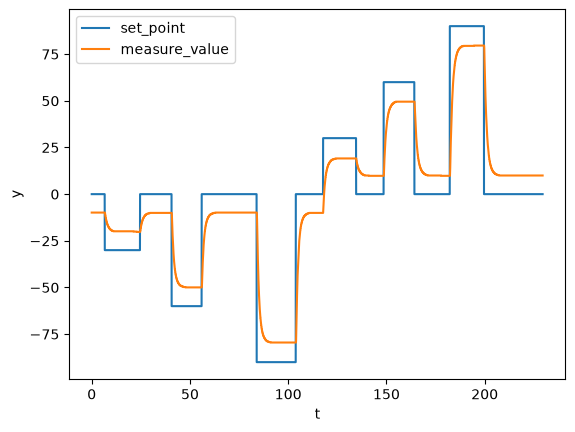

In [4]:
turn = data["fr_turn_pid_ground"].sort("time_s")
# turn = data["fr_prop_pid"].sort("time_s")

_, ax = plt.subplots()
ax.plot(turn["time_s"], turn["set_point"], label="set_point")
ax.plot(turn["time_s"], turn["measure_value"], label="measure_value")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.legend()


## Identyfikacja obiektu w pętli z regulatorem P

Regulator w logu jest proporcjonalny. `P` nie jest dopasowywane: bierze się je z zapisu jako medianę `p_term / error`. Z samego przebiegu widać tylko iloczyn `P·K` i próg `Fc / P`.

Na końcu każdego skoku błąd ustalony ma stałą wartość około 9°, niezależnie od wysokości skoku. Liniowy obiekt inercyjny (typ 0) dałby błąd proporcjonalny do nastawy. Taki stały próg to strefa nieczułości na wejściu obiektu: tarcie Coulomba. Obiekt staje, gdy `|u|` spadnie poniżej progu, czyli przy `|r − y| = Fc / Kp`.

Dopasowanie jest w bibliotece `plantid`. Katalog to obiekt inercyjny 1.–3. rzędu, z tarciem i bez, oraz obiekt całkujący z jedną i dwiema inercjami. Każdy model jest transmitancją python-control, symulowaną w pętli P na rzeczywistych znacznikach czasu. Wygrywa najmniejszy RMSE.


In [5]:
import plantid

Kp = plantid.loop_gain(turn["error"].to_numpy(), turn["p_term"].to_numpy())
print(f"P zebrane w logu: {Kp:g}")

steps = (
    turn.select("time_s", "set_point", "measure_value", "error", "out")
    .with_columns(
        (pl.col("set_point").diff().abs().fill_null(0.0) > 1.0)
        .cum_sum()
        .alias("segment")
    )
    .group_by("segment", maintain_order=True)
    .agg(
        pl.col("time_s").min().alias("t_start"),
        (pl.col("time_s").max() - pl.col("time_s").min()).alias("duration_s"),
        pl.col("set_point").last(),
        pl.col("measure_value").last().alias("y_end"),
        pl.col("error").last().alias("e_end"),
        pl.col("out").last().alias("u_end"),
    )
)
steps


P zebrane w logu: 1


segment,t_start,duration_s,set_point,y_end,e_end,u_end
u32,f64,f64,f64,f64,f64,f64
0,0.0,6.594901,-0.0,-9.875488,9.875488,9.875488
1,6.610069,17.940406,-30.0,-20.246582,-9.753418,-9.753418
2,24.56551,16.053768,-0.0,-10.05127,10.05127,10.05127
3,40.634449,15.279896,-60.0,-49.953613,-10.046387,-10.046387
4,55.929515,27.970552,-0.0,-9.875488,9.875488,9.875488
…,…,…,…,…,…,…
8,134.528852,14.004711,-0.0,9.812012,-9.812012,-9.812012
9,148.54873,15.614736,60.0,49.538574,10.461426,10.461426
10,164.178632,18.015896,-0.0,9.812012,-9.812012,-9.812012


In [6]:
import plantid

t = turn["time_s"].to_numpy()
r = turn["set_point"].to_numpy()
y = turn["measure_value"].to_numpy()

found = plantid.search(t, r, y, plantid.default_models(), kp=Kp)
found.table


model,P,G(s),Fc,rmse,at_bound
str,f64,str,f64,f64,bool
"""inercyjny 3 + tarcie""",1.0,"""321.2 / (427 s + 1)(0.06892 s …",10.160935,0.504682,false
"""inercyjny 2 + tarcie""",1.0,"""319 / (423.2 s + 1)(0.1361 s +…",10.159363,0.517256,false
"""całkujący, inercja 2 + tarcie""",1.0,"""0.7504 / (s (0.06783 s + 1)(0.…",10.149869,0.532249,false
"""całkujący, inercja 1 + tarcie""",1.0,"""0.7519 / (s (0.1335 s + 1))""",10.147072,0.544652,false
"""inercyjny 1 + tarcie""",1.0,"""394 / (531.3 s + 1)""",9.965277,0.827163,false
"""całkujący + tarcie""",1.0,"""0.7407 / s""",9.968448,0.837262,false
"""inercyjny 1""",1.0,"""7.341 / (14.61 s + 1)""",null,7.227842,false
"""inercyjny 2""",1.0,"""7.339 / (14.61 s + 1)(0.000911…",null,7.228518,true
"""inercyjny 3""",1.0,"""7.336 / (14.6 s + 1)(0.0009119…",null,7.229197,true


In [7]:
best = found.best
Fc = best.fc if best.fc is not None else 0.0
G = best.system
G_cl = plantid.closed_loop(G, Kp)

print(best.model.name)
print(f"P = {best.kp:g}")
print(f"G(s) = {best.formula()}")
print(f"Fc = {Fc:.3f}   RMSE = {best.rmse:.3f}   parametr na ograniczeniu: {best.at_bound}")
print("pętla liniowa, bez tarcia:")
print(G_cl)
found.table


inercyjny 3 + tarcie
P = 1
G(s) = 321.2 / (427 s + 1)(0.06892 s + 1)(0.06889 s + 1)
Fc = 10.161   RMSE = 0.505   parametr na ograniczeniu: False
pętla liniowa, bez tarcia:
<TransferFunction>: sys[422]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                   321.2
  ---------------------------------------
  2.027 s^3 + 58.84 s^2 + 427.1 s + 322.2


model,P,G(s),Fc,rmse,at_bound
str,f64,str,f64,f64,bool
"""inercyjny 3 + tarcie""",1.0,"""321.2 / (427 s + 1)(0.06892 s …",10.160935,0.504682,false
"""inercyjny 2 + tarcie""",1.0,"""319 / (423.2 s + 1)(0.1361 s +…",10.159363,0.517256,false
"""całkujący, inercja 2 + tarcie""",1.0,"""0.7504 / (s (0.06783 s + 1)(0.…",10.149869,0.532249,false
"""całkujący, inercja 1 + tarcie""",1.0,"""0.7519 / (s (0.1335 s + 1))""",10.147072,0.544652,false
"""inercyjny 1 + tarcie""",1.0,"""394 / (531.3 s + 1)""",9.965277,0.827163,false
"""całkujący + tarcie""",1.0,"""0.7407 / s""",9.968448,0.837262,false
"""inercyjny 1""",1.0,"""7.341 / (14.61 s + 1)""",null,7.227842,false
"""inercyjny 2""",1.0,"""7.339 / (14.61 s + 1)(0.000911…",null,7.228518,true
"""inercyjny 3""",1.0,"""7.336 / (14.6 s + 1)(0.0009119…",null,7.229197,true


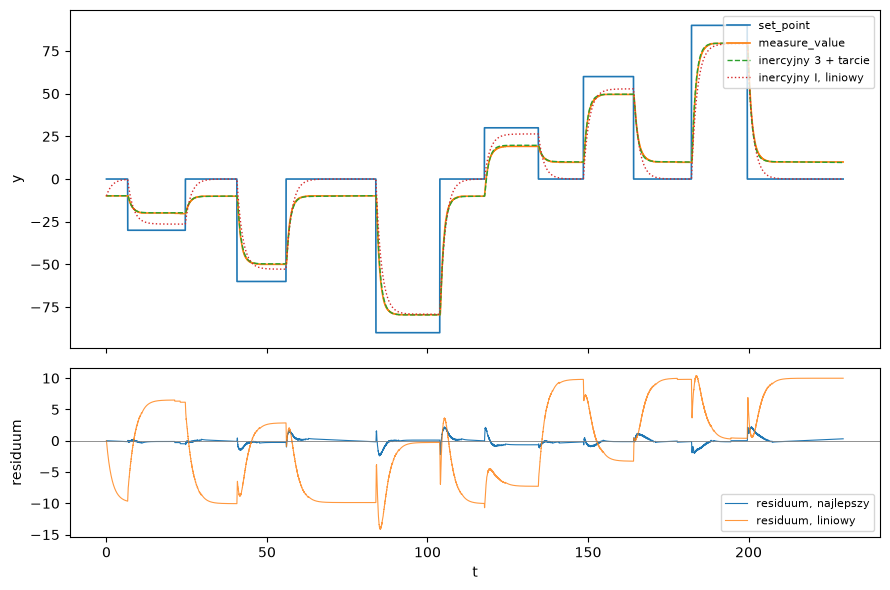

In [8]:
linear = next(item for item in found.results if item.model.name == "inercyjny 1")

fig, axes = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": (2, 1)}
)
axes[0].plot(t, r, label="set_point", lw=1.2)
axes[0].plot(t, y, label="measure_value", lw=1.2)
axes[0].plot(t, best.prediction, ls="--", label=best.model.name, lw=1.0)
axes[0].plot(t, linear.prediction, ls=":", label="inercyjny I, liniowy", lw=1.0)
axes[0].set_ylabel("y")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t, y - best.prediction, label="residuum, najlepszy", lw=0.8)
axes[1].plot(t, y - linear.prediction, label="residuum, liniowy", lw=0.8, alpha=0.8)
axes[1].axhline(0.0, color="0.5", lw=0.6)
axes[1].set_xlabel("t")
axes[1].set_ylabel("residuum")
axes[1].legend(fontsize=8)
fig.tight_layout()


## Nastawy PID pod implementację z firmware

Dobór PID nie korzysta z wyniku identyfikacji. Obiekt podaje się w następnej komórce jako `Plant` (wzmocnienie, stałe czasowe, tarcie). Regulator jest pętlą pozycji z `Src/PID/PID.cpp`, wołaną co `ControlLoopDurationUS = 15000` (15 ms). Benchmark to sekwencja z logu: 0, −30, 0, −60, 0, −90, 0, +30, 0, +60, 0, +90, 0. Jedna iteracja:

1. `error = set_point - measure`, wyzerowany gdy `|error| < DeadZone`
2. `acc = clamp(error + (1 - SmoothingFactor) * acc, ±AntiWindup)`
3. `p = Kp * error`, `i = acc * dt * Ki`, `d = Kd * (error - error_prev) / dt`
4. `out` obcięte do `[±MaxOutput]`, a poniżej `MinOutput` podbite do tej wartości

`DeadZone` ustawiasz w następnej komórce. `SmoothingFactor = 0` zostaje, bo tylko wtedy `acc` jest sumą błędu i człon I potrafi dociągnąć przez tarcie. Przy `AntiWindup = 100` maksymalny wkład całki to `i_max = 100 * dt * Ki`. Żeby w spoczynku pokonać tarcie, potrzeba `i_max > Fc`. Człon D jest liczony z błędu, więc skok nastawy daje jeden impuls `Kd * skok / dt`.

Dobór woła `scipy.optimize.minimize` w granicach `Kp`, `Ki`, `Kd`. Koszt to ISE, `We * sum((setpoint - y)**2) * dt`. `allow_steady_state_error=False` nie schodzi z `Ki` poniżej wartości, przy której `i_max = AntiWindup * dt * Ki` pokrywa `Fc + |nastawa| / K` (dla obiektu całkującego samo `Fc`). Górny kraniec zakresu jest twardy. `allow_steady_state_error=True` szuka po całym podanym zakresie i zostawia lekką półkę, jeśli tak wychodzi mniejsze ISE. Porównywane są dolny kraniec, środek i górny kraniec każdego wzmocnienia.


In [ ]:
# Obiekt pod dobór PID. Ta komórka nie czyta wyniku identyfikacji.
# Napedy
# DeadZone = 0.1  # firmware DeadZone
# Kp = (40.0, 130.0)
# Ki = (0.1, 30.0)
# Kd = (0.0, 0.1)
# We = 1.0   # weight on squared error
# AllowSteadyStateError = True  # napędy: lekki uchyb dozwolony
# Skręty
DeadZone = 0 # firmware DeadZone
Kp = (0.0, 7.0)
Ki = (0.0, 3.0)
Kd = (0.0, 0.5)
We = 100.0   # weight on ISE
AllowSteadyStateError = False  # skręty: bez uchybu

pid_plant = best.plant
tuned = plantid.tune(
    pid_plant,
    dead_zone=DeadZone,
    kp=Kp,
    ki=Ki,
    kd=Kd,
    we=We,
    max_overshoot=4.0,
    allow_steady_state_error=AllowSteadyStateError,
)
print(tuned)
tuned.steps


Kp = 4.461   Ki = 6.994   Kd = 0.25
ISE = 2.542e+06   We = 100
i_max = AntiWindup * dt * Ki = 10.49   Fc = 10.16
ITAE 228   overshoot 1.36   |e|_end 0.143


regulator,setpoint,itae,overshoot_deg,abs_final_deg
str,f64,f64,f64,f64
"""Kp=1, Ki=0, Kd=0""",0.0,0.0,0.0,0.0
"""Kp=1, Ki=0, Kd=0""",-30.0,212.805,0.0,10.355871
"""Kp=1, Ki=0, Kd=0""",0.0,196.014822,0.0,10.211386
"""Kp=1, Ki=0, Kd=0""",-60.0,243.640571,0.0,10.581717
"""Kp=1, Ki=0, Kd=0""",0.0,240.087814,0.0,10.391097
…,…,…,…,…
"""Kp=4.46097, Ki=6.99368, Kd=0.2…",0.0,5.160342,0.139566,0.138268
"""Kp=4.46097, Ki=6.99368, Kd=0.2…",60.0,13.724991,0.079082,0.12521
"""Kp=4.46097, Ki=6.99368, Kd=0.2…",0.0,15.129854,0.140583,0.139421


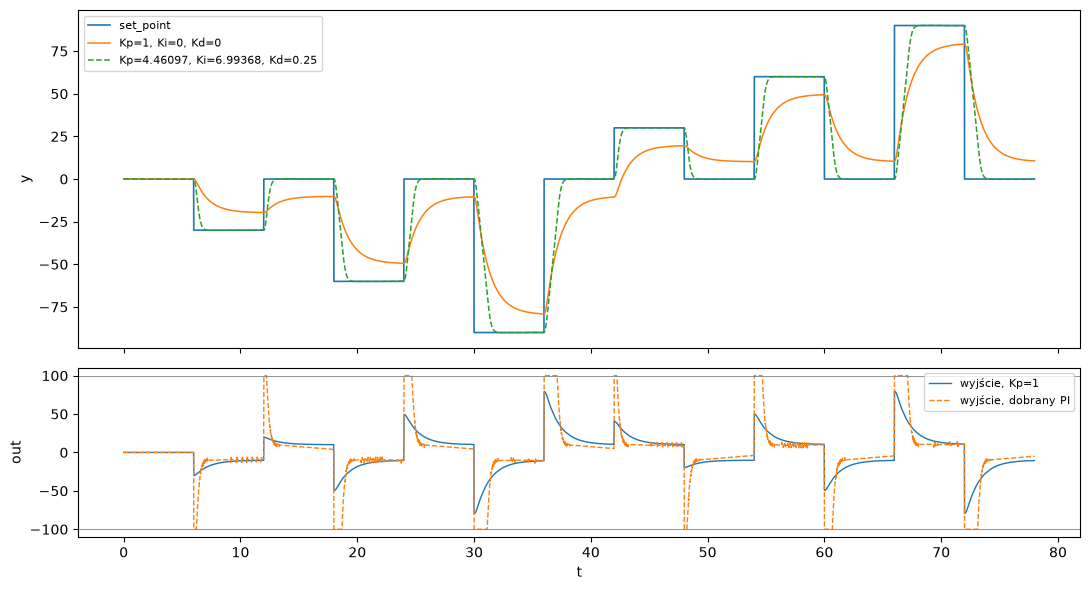

In [38]:
show_ref = tuned.reference
show_t = np.arange(len(show_ref)) * tuned.dt

y_base, u_base = plantid.simulate(
    pid_plant,
    show_ref,
    plantid.Gains(1.0, 0.0, 0.0),
    dt=tuned.dt,
    dead_zone=DeadZone,
)
y_pi, u_pi = tuned.response, tuned.output

fig, axes = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": (2, 1)}
)
axes[0].plot(show_t, show_ref, label="set_point", lw=1.2)
axes[0].plot(show_t, y_base, label="Kp=1, Ki=0, Kd=0", lw=1.1)
axes[0].plot(
    show_t,
    y_pi,
    ls="--",
    label=f"Kp={tuned.gains.kp:g}, Ki={tuned.gains.ki:g}, Kd={tuned.gains.kd:g}",
    lw=1.1,
)
axes[0].set_ylabel("y")
axes[0].legend(loc="best", fontsize=8)

axes[1].plot(show_t, u_base, label="wyjście, Kp=1", lw=1.0)
axes[1].plot(show_t, u_pi, ls="--", label="wyjście, dobrany PI", lw=1.0)
axes[1].axhline(tuned.limits.max_output, color="0.5", lw=0.6)
axes[1].axhline(-tuned.limits.max_output, color="0.5", lw=0.6)
axes[1].set_xlabel("t")
axes[1].set_ylabel("out")
axes[1].legend(loc="best", fontsize=8)
fig.tight_layout()
